# Metastatic-origin overall survival in the common MCPP cohort

This observational analysis compares survival by phenotype at first metastatic diagnosis and evaluates the same eight frozen genes as a secondary prognostic analysis. It does not retrain predictive models or redefine the primary gene set. See the linked [expression characterization](20260924-mcpp-model-prioritized-gene-expression-characterization.ipynb).

In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display

from pathlib import Path
import sys
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.display import Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import inputs, prepare_endpoint, fit_cox, plot_km, plot_ph, save_table, save_figure, save_json
from scripts.OligoPolyThesis.utils_ml_oligopoly import plot_thesis_saved_figure
BASE = Path('/mnt/data3/MCPP-Breast')
OUTPUT_ROOT = BASE / 'Machine-Learning-Models-poly_vs_oligo/MCPP-Biological-Characterization/common-110'
INPUTS = inputs(BASE)
RANDOM_STATE = 42
STARTED = datetime.now(timezone.utc).isoformat()

OUT = OUTPUT_ROOT / 'survival'
OUT.mkdir(parents=True, exist_ok=True)
RESULTS = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/MCPP-Biological-Characterization/common-110/harmonised_main8')
primary = pd.read_csv(RESULTS / 'harmonised_only_main8_manifest.csv')
cohort = pd.read_csv(BASE / 'Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/private/common_patients.csv')
cohort['sample_key'] = cohort.sample_id.str.strip().str.upper()
cohort = cohort.set_index('sample_key')

## Endpoint definition and quality control

Overall survival starts at `abc_m1_diagnosis`. Recorded `death_date` defines an all-cause event; otherwise the observed `last_fu` supplies censoring. No administrative date is substituted. Models use days; figures show days/30.4375 months. Age is elapsed days from birth to metastatic diagnosis divided by 365.25.

Baseline oligo patients remain in that group after subsequent poly progression. Date-derived event status depends on record completeness. Chronological and linkage checks must pass and be saved before fitting. No exclusions beyond endpoint validity are applied.

The metastatic time origin describes survival after metastatic disease begins and relates directly to the baseline oligo/poly state. OS from primary diagnosis would additionally include the pre-metastatic interval. The complementary primary-origin analysis below uses those dates and explicitly addresses selection of patients who survived to metastatic diagnosis.


In [2]:
survival, endpoint_summary, endpoint_checks = prepare_endpoint(INPUTS, cohort)
save_table(endpoint_summary, OUT / 'endpoint_qc_summary.csv')
save_json(endpoint_checks, OUT / 'endpoint_qc_checks.json')
thesis_display(endpoint_summary)
thesis_display(pd.DataFrame([endpoint_checks]))

,baseline_polymetastatic,N,deaths,censored,group
0,0,43,31,12,Oligometastatic
1,1,67,53,14,Polymetastatic


,invalid_nonmissing_dates,missing_duration,nonpositive_duration,birth_after_primary,primary_after_metastatic,both_death_and_followup,oligo_origin_mismatch,progression_outside_followup,N,deaths,censored,baseline_oligo_later_progressed,reference_group
0,0,0,0,0,0,0,0,0,110,84,26,30,baseline oligometastatic; later progression do...


### Endpoint availability

All 110 patients had valid positive follow-up durations: 31 deaths and 12 censored in baseline oligo, and 53 deaths and 14 censored in baseline poly. All specified linkage and chronological checks passed. Thirty baseline oligo patients later progressed to poly and remain classified as oligo here.

## Baseline phenotype: Kaplan–Meier and log-rank

Curves show 95% confidence bands and censoring marks. The risk table gives patients at risk at the start of each displayed 12-month interval. Median survival and its confidence limits are reported in months; an infinite estimate means the median or interval boundary was not reached.

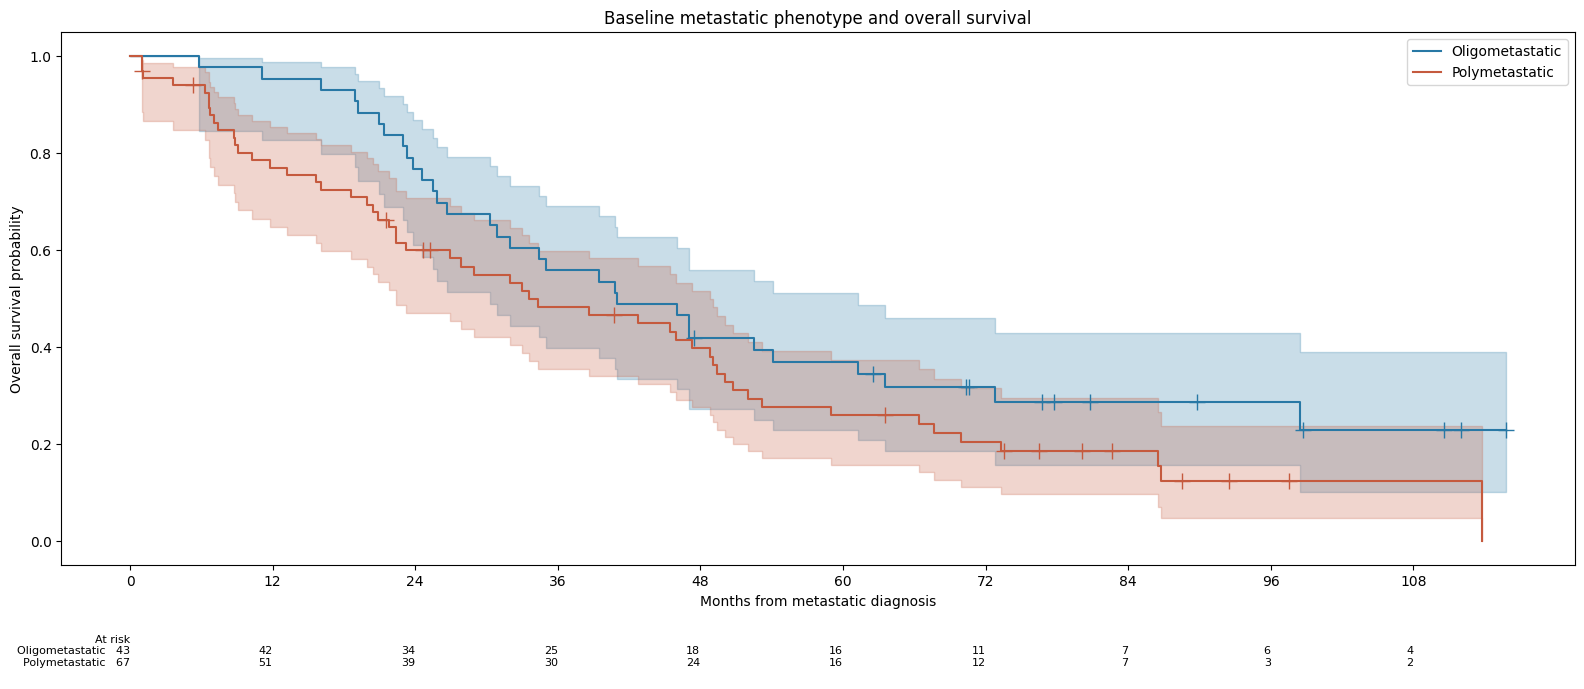

,group,N,events,median_OS_months,median_CI_lower,median_CI_upper
0,Oligometastatic,43,31,41.002,30.292,61.273
1,Polymetastatic,67,53,33.544,22.407,48.821


,test,chi_squared,p_value,N,events
0,two-sided log-rank,2.865,0.0905,110,84


In [3]:
fig, km_summary, logrank_results = plot_km(survival)
save_figure(fig, OUT / 'baseline_phenotype_km.png')
save_table(km_summary, OUT / 'baseline_phenotype_km_summary.csv')
save_table(logrank_results, OUT / 'baseline_phenotype_logrank.csv')
plt.show()
thesis_display(km_summary)
thesis_display(logrank_results)

### Survival by baseline phenotype

Median OS was 41.0 months (95% CI 30.3–61.3) for oligo and 33.5 months (22.4–48.8) for poly. The log-rank p-value was 0.0905. Poly patients had numerically shorter OS, but uncertainty is substantial, especially late in follow-up when few patients remain at risk. This does not establish a survival difference or equivalence.

## Unadjusted Cox model and proportional hazards

`OS ~ baseline_polymetastatic`, with oligometastatic disease as reference. HR >1 denotes higher mortality hazard in baseline poly. The rank-time PH test and scaled Schoenfeld residuals are diagnostics. A PH p-value <0.05 is flagged and qualifies interpretation of a single HR; no time-varying model is introduced.

This Cox model estimates an association (the hazard of death for baseline polymetastatic versus oligometastatic disease), not predictive survival performance. It is not a multigene predictor.


,model,term,N,events,coefficient,HR,CI_lower,CI_upper,p_value,PH_p_value,PH_violation_flag
0,unadjusted_baseline_phenotype,baseline_polymetastatic,110,84,0.382,1.465,0.938,2.288,0.0930,0.476,False


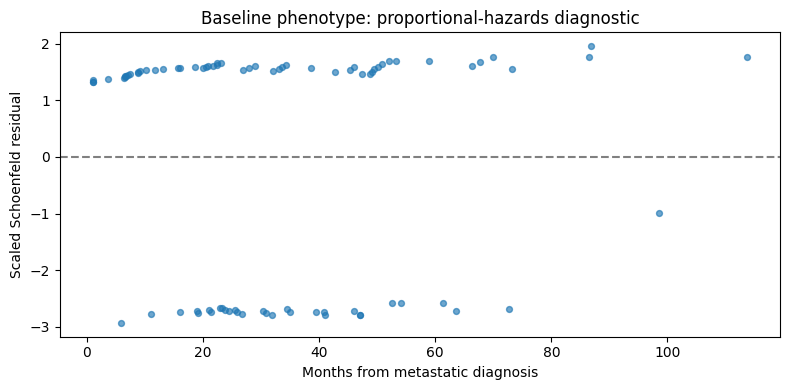

In [4]:
phenotype_model, phenotype_results = fit_cox(survival, ['baseline_polymetastatic'], 'unadjusted_baseline_phenotype')
save_table(phenotype_results, OUT / 'baseline_phenotype_cox.csv')
save_table(phenotype_results[['term','PH_p_value','PH_violation_flag']], OUT / 'baseline_phenotype_ph_diagnostics.csv')
thesis_display(phenotype_results)
fig = plot_ph(phenotype_model, survival)
save_figure(fig, OUT / 'baseline_phenotype_schoenfeld.png')
plt.show()

### Unadjusted hazard ratio and PH diagnostic

The poly-versus-oligo HR was 1.465 (95% CI 0.938–2.288; p = 0.0930). The interval includes both little difference and a clinically substantial increase in hazard. The rank-time Schoenfeld diagnostic gave p = 0.476; no violation was detected at the prespecified 0.05 threshold, although this does not prove proportional hazards.

## Eight model-prioritised genes: overall-survival associations

Eight separate unadjusted Cox models use standardized log2(TPM + 1), sample SD, Wald intervals, eight-test BH and rank-time proportional-hazards tests. These observational secondary associations do not validate the predictive classifier.

In [ ]:
display(pd.read_csv(RESULTS / 'harmonised_only_main8_metastatic_OS_cox.csv')[['gene_symbol', 'N', 'events', 'HR', 'CI_lower', 'CI_upper', 'p_value', 'q_value', 'PH_p_value', 'PH_violation_flag', 'BH_family_size']].style.format(precision=3))

gene_symbol,N,events,HR,CI_lower,CI_upper,p_value,q_value,PH_p_value,PH_violation_flag,BH_family_size
H3C14,110,84,1.26,1.01,1.57,0.0424,0.169,0.358,False,8
KIAA2012,110,84,0.934,0.759,1.15,0.515,0.824,0.18,False,8
MYEOV,110,84,1.04,0.831,1.29,0.758,0.866,0.705,False,8
TMPRSS4,110,84,0.9,0.732,1.11,0.315,0.824,0.499,False,8
ZNF549,110,84,0.998,0.804,1.24,0.982,0.982,0.718,False,8
GDAP1,110,84,0.927,0.765,1.12,0.444,0.824,0.12,False,8
RUNDC3B,110,84,0.957,0.772,1.19,0.686,0.866,0.819,False,8
ZNF205,110,84,0.814,0.669,0.992,0.0412,0.169,0.96,False,8


No metastatic-origin gene association survives BH correction. H3C14 (HR=1.258) and ZNF205 (HR=0.814) are nominally associated, both q=0.169. None of the eight has a PH diagnostic p<0.05.

## Metastatic-origin gene estimates

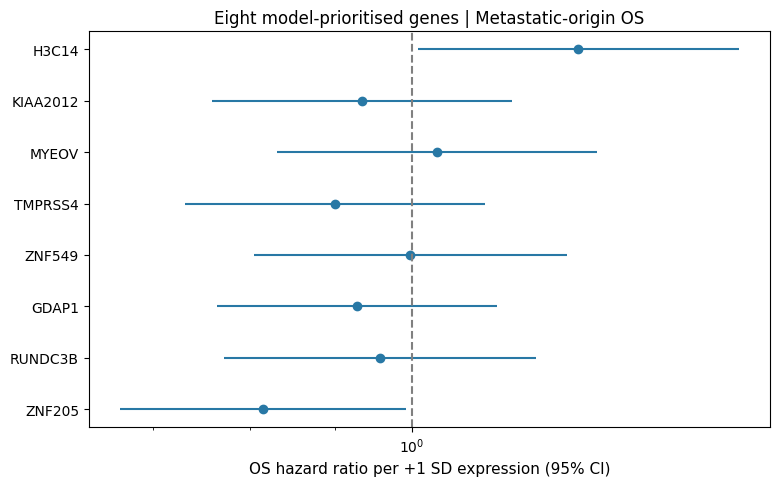

In [27]:
fig = plot_thesis_saved_figure('cox', 'metastatic')
plt.show()


## Limitations

Baseline phenotype–survival associations are observational, not causal. The molecular cohort is retrospectively selected and dependent on tissue/data availability. Date-derived censoring assumes records correctly distinguish deaths from last follow-up. Non-informative censoring and the Cox functional form remain assumptions; PH tests have limited power.

Genes were selected using the same patients’ oligo/poly phenotype. A different endpoint reduces direct outcome circularity but does not make internal OS analysis independent external validation. BH corrections do not account for the earlier model-based gene selection. The frozen primary list remains unchanged; TP53AIP1 belongs only to the secondary expression/TCGA context.

In [ ]:
display(pd.read_csv(RESULTS / 'harmonised_only_main8_manifest.csv'))

## Complementary overall survival from primary diagnosis

This analysis retains the same 110 patients, 84 deaths, 26 censored observations and baseline metastatic phenotype. Time starts at primary breast cancer diagnosis; death is an all-cause event and living patients are censored at last follow-up. Date validity and chronology checks passed. Unlike metastatic-origin OS, this endpoint includes the pre-metastatic interval. Because the cohort and phenotype are defined at metastatic diagnosis, these curves condition on reaching that diagnosis; they do not describe prognosis in an unselected primary breast cancer population.

Median OS was 88.411 months for OMD and 76.255 months for PMD (log-rank p=0.154). The unadjusted PMD-versus-OMD HR was 1.379 (95% CI 0.885–2.149; p=0.156). The adjusted HR was 1.415 (0.906–2.211; p=0.127). For consistency, adjustment retains age at metastatic diagnosis; it is not a baseline primary-diagnosis prediction model. Neither analysis provides strong evidence of a phenotype–mortality association. The existing metastatic-origin unadjusted HR was 1.465 (0.938–2.288; p=0.093).

### Association-model diagnostics

No rank-time PH test flagged the phenotype or age terms at p<0.05 for either origin. Failure to detect a violation does not prove proportional hazards. C-indices below are apparent, in-sample concordance, not external or cross-validated performance. The original metastatic-origin estimates were numerically verified during diagnostic reconstruction; their artifacts remain unchanged.


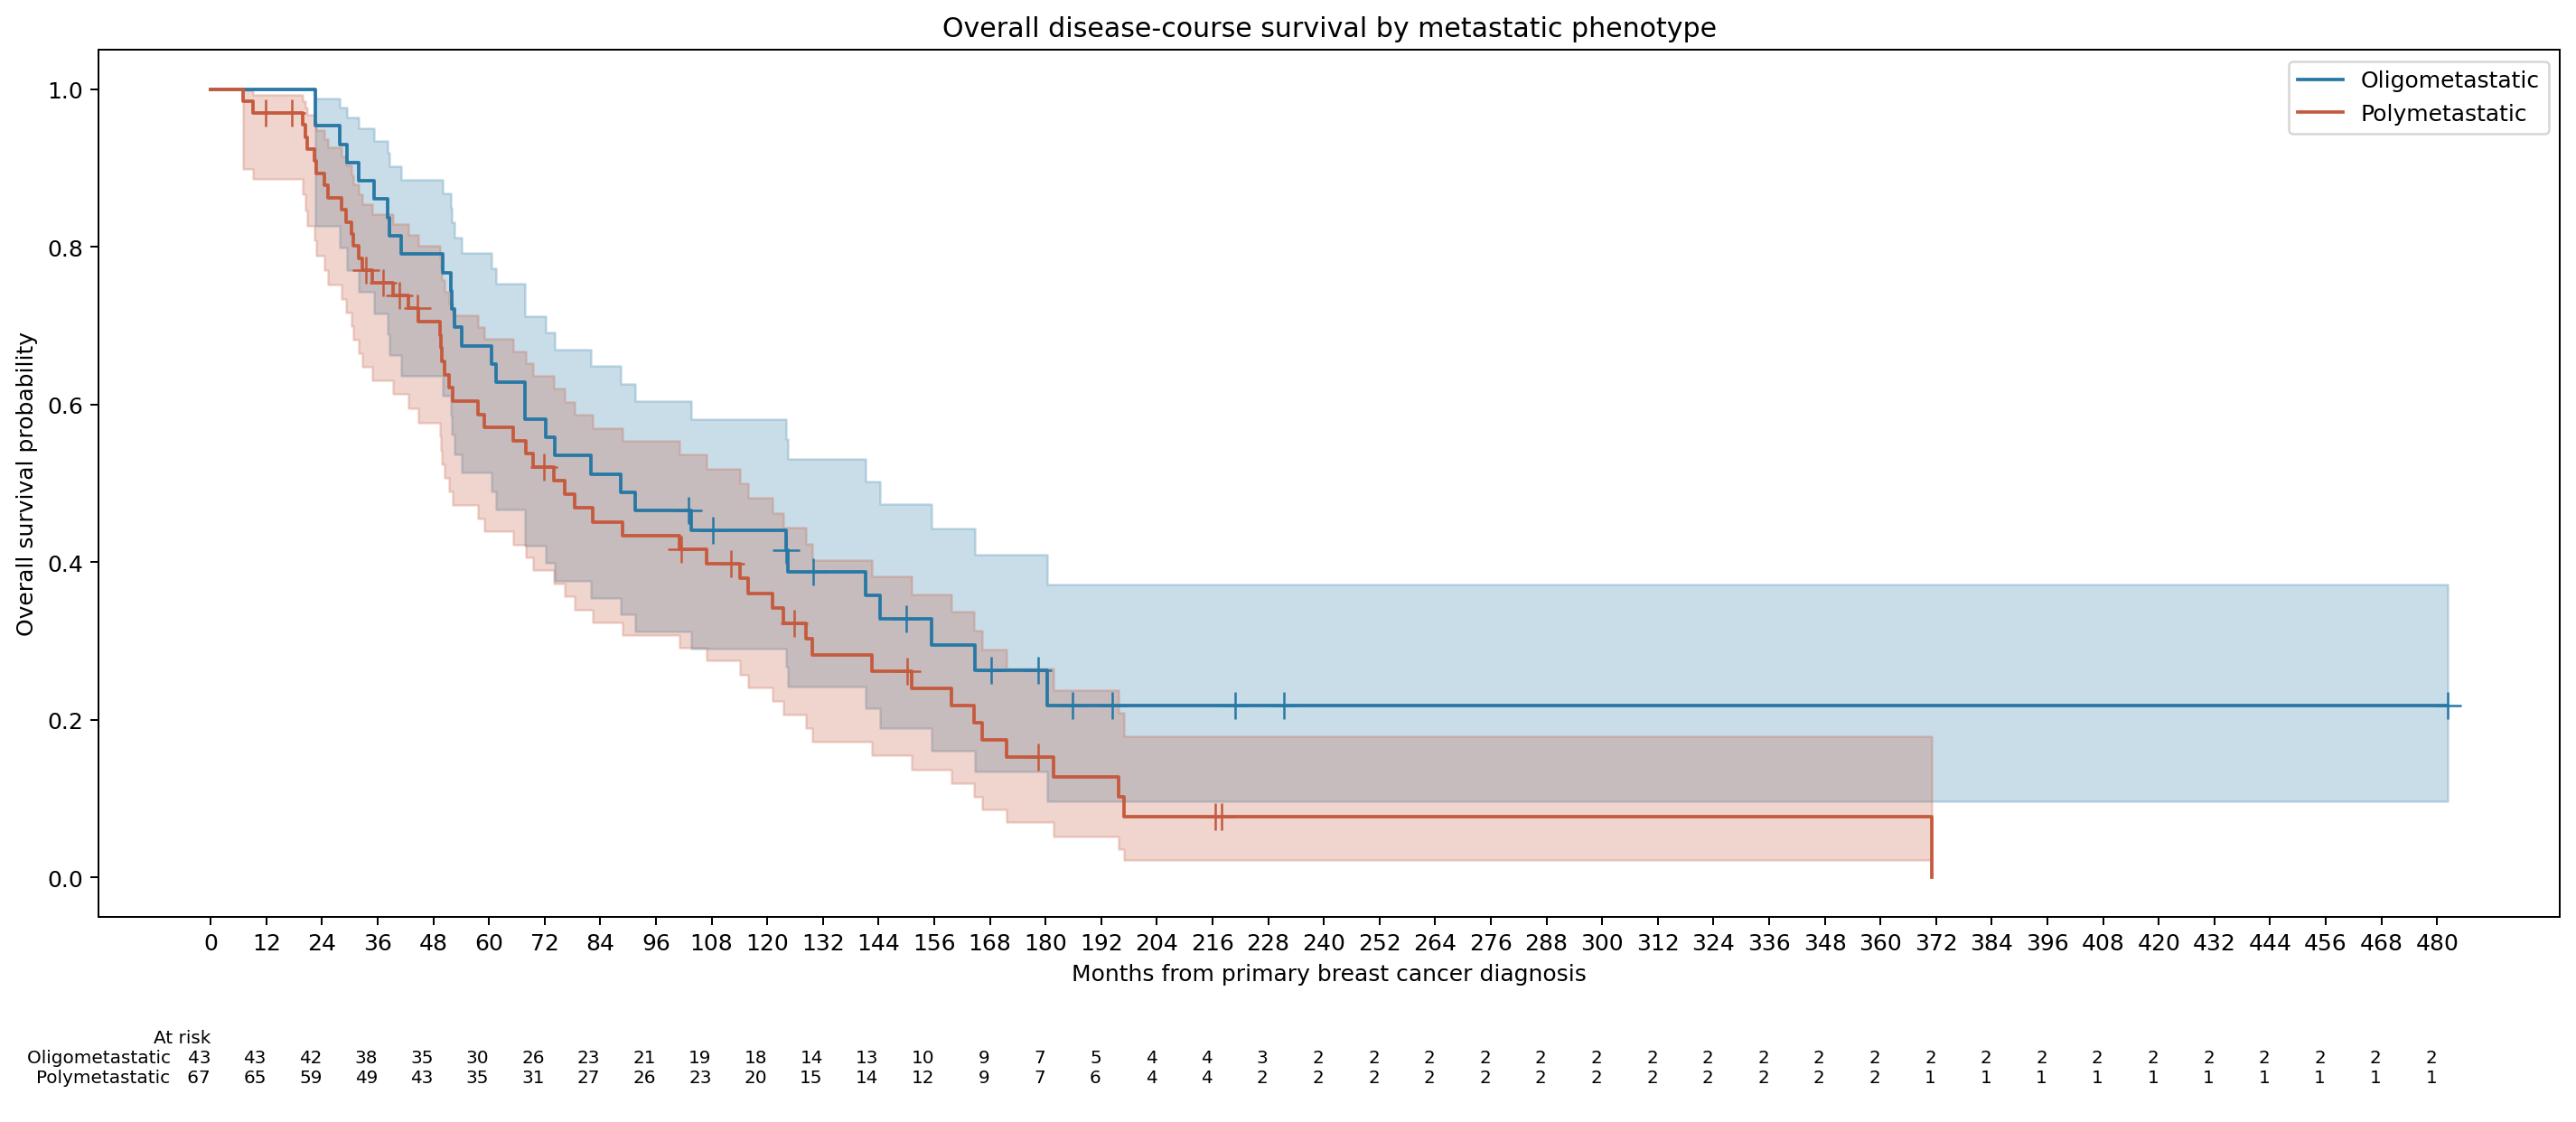

group,N,events,median_OS_months,median_CI_lower,median_CI_upper
Oligometastatic,43,31,88.411,60.485,144.329
Polymetastatic,67,53,76.255,51.318,115.778


test,chi_squared,p_value,N,events
two-sided log-rank,2.032,0.154,110,84


model,term,N,events,coefficient,HR,CI_lower,CI_upper,p_value,PH_p_value,PH_violation_flag,origin,apparent_C_index
metastatic_unadjusted,baseline_polymetastatic,110,84,0.382,1.465,0.938,2.288,0.093,0.476,False,metastatic,0.553
metastatic_age_adjusted,baseline_polymetastatic,110,84,0.379,1.461,0.935,2.282,0.096,0.504,False,metastatic,0.560
metastatic_age_adjusted,age_at_metastatic_diagnosis,110,84,0.008,1.008,0.991,1.025,0.368,0.916,False,metastatic,0.560
primary_unadjusted,baseline_polymetastatic,110,84,0.321,1.379,0.885,2.149,0.156,0.957,False,primary,0.537
primary_age_adjusted,baseline_polymetastatic,110,84,0.347,1.415,0.906,2.211,0.127,0.963,False,primary,0.559
primary_age_adjusted,age_at_metastatic_diagnosis,110,84,-0.008,0.992,0.976,1.008,0.307,0.729,False,primary,0.559


In [ ]:
# Display preserved complementary survival results; no fitting occurs here.
SUPPLEMENT = OUT  # saved common-110/survival results
thesis_display(Image(filename=str(SUPPLEMENT / 'primary_origin_km.png')))
thesis_display(pd.read_csv(SUPPLEMENT / 'primary_origin_km_summary.csv'))
thesis_display(pd.read_csv(SUPPLEMENT / 'primary_origin_logrank.csv'))
thesis_display(pd.read_csv(SUPPLEMENT / 'phenotype_cox_diagnostics_metastatic_and_primary_origin.csv'))


## Primary-diagnosis-origin gene OS: sensitivity analysis

The same 110 patients and 84 deaths are used. Phenotype and inclusion are established during the metastatic course after primary diagnosis; selection and time-origin limitations prevent interpreting this as prediction at primary diagnosis.

In [ ]:
display(pd.read_csv(RESULTS / 'harmonised_only_main8_primary_OS_cox.csv')[['gene_symbol', 'N', 'events', 'HR', 'CI_lower', 'CI_upper', 'p_value', 'q_value', 'PH_p_value', 'PH_violation_flag', 'BH_family_size']].style.format(precision=3))

gene_symbol,N,events,HR,CI_lower,CI_upper,p_value,q_value,PH_p_value,PH_violation_flag,BH_family_size
H3C14,110,84,1.3,1.04,1.62,0.0205,0.164,0.0492,True,8
KIAA2012,110,84,1,0.816,1.22,0.997,0.997,0.608,False,8
MYEOV,110,84,0.99,0.799,1.23,0.927,0.997,0.809,False,8
TMPRSS4,110,84,0.935,0.758,1.15,0.534,0.963,0.27,False,8
ZNF549,110,84,1.12,0.904,1.39,0.299,0.963,0.408,False,8
GDAP1,110,84,0.991,0.823,1.19,0.922,0.997,0.85,False,8
RUNDC3B,110,84,0.945,0.765,1.17,0.602,0.963,0.884,False,8
ZNF205,110,84,0.934,0.766,1.14,0.496,0.963,0.743,False,8


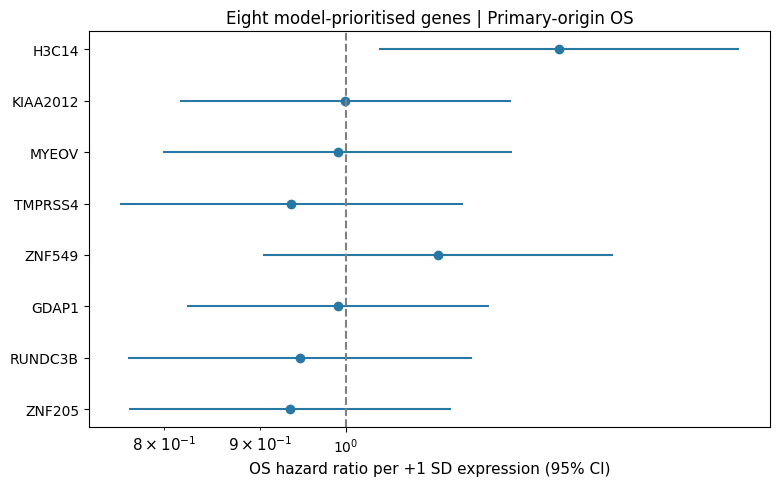

In [28]:
fig = plot_thesis_saved_figure('cox', 'primary')
plt.show()


No primary-origin gene association survives BH correction. H3C14 has HR=1.299 (95% CI 1.041–1.622), p=0.0205, q=0.164, with a PH diagnostic flag (p=0.0492). The other seven genes have no nominal PH flag. Phenotype-level survival results are unchanged.